In [1]:
import os
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
%matplotlib qt

In [59]:
import re
import numpy as np
import matplotlib.pyplot as plt

# Raw text pasted as a multiline string
text = """
Scan:1 #BadChannels:9
Scan:2 #BadChannels:17
Scan:3 #BadChannels:11
Scan:4 #BadChannels:7
Scan:5 #BadChannels:6
Scan:6 #BadChannels:24
Scan:7 #BadChannels:26
Scan:8 #BadChannels:18
Scan:9 #BadChannels:11
Scan:10 #BadChannels:11
Scan:11 #BadChannels:27
Scan:12 #BadChannels:7
Scan:13 #BadChannels:20
Scan:14 #BadChannels:7
Scan:15 #BadChannels:14
Scan:16 #BadChannels:13
Scan:17 #BadChannels:19
Scan:18 #BadChannels:3
Scan:19 #BadChannels:7
Scan:20 #BadChannels:12
Scan:21 #BadChannels:18
Scan:22 #BadChannels:18
Scan:23 #BadChannels:13
Scan:24 #BadChannels:24
Scan:25 #BadChannels:11
Scan:26 #BadChannels:19
Scan:27 #BadChannels:26
Scan:28 #BadChannels:18
Scan:29 #BadChannels:8
Scan:30 #BadChannels:12
Scan:31 #BadChannels:22
Scan:32 #BadChannels:12
Scan:33 #BadChannels:16
Scan:34 #BadChannels:1
Scan:35 #BadChannels:11
Scan:36 #BadChannels:1
Scan:37 #BadChannels:20
Scan:38 #BadChannels:4
Scan:39 #BadChannels:30
Scan:40 #BadChannels:7
Scan:41 #BadChannels:32
Scan:42 #BadChannels:6
Scan:43 #BadChannels:26
Scan:44 #BadChannels:32
Scan:45 #BadChannels:22
Scan:46 #BadChannels:21
Scan:47 #BadChannels:5
Scan:48 #BadChannels:31
Scan:49 #BadChannels:8
Scan:50 #BadChannels:28
Scan:51 #BadChannels:9
Scan:52 #BadChannels:3
Scan:53 #BadChannels:25
Scan:54 #BadChannels:26
Scan:55 #BadChannels:25
Scan:56 #BadChannels:28
Scan:57 #BadChannels:13
Scan:58 #BadChannels:36
Scan:59 #BadChannels:6
Scan:60 #BadChannels:20
Scan:61 #BadChannels:6
Scan:62 #BadChannels:15
Scan:63 #BadChannels:15
Scan:64 #BadChannels:17
Scan:65 #BadChannels:6
Scan:66 #BadChannels:21
Scan:67 #BadChannels:21
Scan:68 #BadChannels:35
Scan:69 #BadChannels:13
Scan:70 #BadChannels:18
Scan:71 #BadChannels:6
Scan:72 #BadChannels:12
Scan:73 #BadChannels:23
Scan:74 #BadChannels:6
Scan:75 #BadChannels:19
Scan:76 #BadChannels:11
Scan:77 #BadChannels:21
Scan:78 #BadChannels:25
Scan:79 #BadChannels:8
Scan:80 #BadChannels:8
Scan:81 #BadChannels:30
Scan:82 #BadChannels:16
Scan:83 #BadChannels:26
Scan:84 #BadChannels:14
"""

# Extract all bad channel values using regex
bad_channels = list(map(int, re.findall(r"#BadChannels:(\d+)", text)))

# Calculate mean and standard deviation
mean_val = np.mean(bad_channels)
std_val = np.std(bad_channels)

# Plot histogram
plt.figure(figsize=(10, 6))
plt.hist(bad_channels, bins=20, edgecolor='black', alpha=0.7)
plt.axvline(mean_val, color='red', linestyle='--', label=f'Mean = {mean_val:.2f}')
plt.axvline(mean_val + std_val, color='orange', linestyle='--', label=f'+1 SD = {mean_val + std_val:.2f}')
plt.axvline(mean_val + 2 * std_val, color='green', linestyle='--', label=f'+2 SD = {mean_val + 2 * std_val:.2f}')

plt.xlabel('Number of Bad Channels')
plt.ylabel('Frequency')
plt.title('Histogram of Bad Channels Across Scans')
plt.legend()
plt.tight_layout()
plt.show()


In [3]:
import os
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# --- Define directories ---
session1_dir = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Session to Session Data\Behavioral Data\Session 1"
session2_dir = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Session to Session Data\Behavioral Data\Session 2"

# --- Function to load and preprocess behavioral data ---
def load_behavioral_data(folder_path, session_label):
    all_data = []
    for file in os.listdir(folder_path):
        if file.endswith('.csv'):
            df = pd.read_csv(os.path.join(folder_path, file)).copy()

            df['SubjectID'] = os.path.splitext(file)[0]
            df['session'] = session_label

            # --- Assign block numbers robustly even if not divisible by 18 ---
            n_trials = len(df)
            block_assignments = np.zeros(n_trials)
            block_indices = np.array_split(np.arange(n_trials), 18)

            for block_num, indices in enumerate(block_indices, start=1):
                block_assignments[indices] = block_num

            df['block'] = block_assignments.astype(int)

            # Assign condition for each block using mode of 'cond' column
            df['block_cond'] = df.groupby('block')['cond'].transform(
                lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
            )

            all_data.append(df)

    return pd.concat(all_data, ignore_index=True)

# --- Load session 1 and 2 data ---
df1 = load_behavioral_data(session1_dir, session_label=1)
df2 = load_behavioral_data(session2_dir, session_label=2)

# --- Combine all data ---
combined = pd.concat([df1, df2], ignore_index=True)

# --- Compute block-level summary stats per session ---
summary = combined.groupby(['SubjectID', 'session', 'block']).agg(
    accuracy=('key_resp_2.corr', 'mean'),
    rt=('key_resp_2.rt', 'mean'),
    cond=('block_cond', 'first')
).reset_index()

# --- Plotting accuracy and RT per block for each session ---
sns.set(style='whitegrid')
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Accuracy Plot
sns.lineplot(data=summary, x='block', y='accuracy', hue='session', marker='o', ax=axes[0])
axes[0].set_title('Accuracy per Block (Session 1 vs Session 2)')
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('')
axes[0].legend(title='Session')

# Reaction Time Plot
sns.lineplot(data=summary, x='block', y='rt', hue='session', marker='o', ax=axes[1])
axes[1].set_title('Reaction Time per Block (Session 1 vs Session 2)')
axes[1].set_ylabel('Reaction Time (s)')
axes[1].set_xlabel('Block Number')
axes[1].legend(title='Session')

plt.tight_layout()
plt.show()



C:\Users\pkell\anaconda3\Lib\site-packages\seaborn\_core.py:991: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\pkell\anaconda3\Lib\site-packages\seaborn\_core.py:991: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\pkell\anaconda3\Lib\site-packages\seaborn\_core.py:991: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\pkell\anaconda3\Lib\site-packages\seaborn\_core.py:991: FutureWa

In [5]:
import os
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# --- Define directories ---
session1_dir = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Session to Session Data\Behavioral Data\Session 1"
session2_dir = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Session to Session Data\Behavioral Data\Session 2"

# --- Function to load and preprocess behavioral data ---
def load_behavioral_data(folder_path, session_label):
    all_data = []
    for file in os.listdir(folder_path):
        if file.endswith('.csv'):
            df = pd.read_csv(os.path.join(folder_path, file)).copy()

            df['SubjectID'] = os.path.splitext(file)[0]
            df['session'] = session_label

            # --- Assign block numbers robustly even if not divisible by 18 ---
            n_trials = len(df)
            block_assignments = np.zeros(n_trials)
            block_indices = np.array_split(np.arange(n_trials), 18)

            for block_num, indices in enumerate(block_indices, start=1):
                block_assignments[indices] = block_num

            df['block'] = block_assignments.astype(int)

            # Assign condition for each block using mode of 'cond' column
            df['block_cond'] = df.groupby('block')['cond'].transform(
                lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
            )

            all_data.append(df)

    return pd.concat(all_data, ignore_index=True)

# --- Load session 1 and 2 data ---
df1 = load_behavioral_data(session1_dir, session_label=1)
df2 = load_behavioral_data(session2_dir, session_label=2)

# --- Combine all data ---
combined = pd.concat([df1, df2], ignore_index=True)

# --- Compute block-level summary stats per participant and session ---
summary = combined.groupby(['SubjectID', 'session', 'block']).agg(
    accuracy=('key_resp_2.corr', 'mean'),
    rt=('key_resp_2.rt', 'mean'),
    cond=('block_cond', 'first')
).reset_index()

# --- Plotting per-participant block accuracy and RT ---
sns.set(style='whitegrid')

unique_subjects = summary['SubjectID'].unique()

for subj in unique_subjects:
    subj_data = summary[summary['SubjectID'] == subj]

    fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

    # Accuracy Plot
    sns.lineplot(data=subj_data, x='block', y='accuracy', hue='session', marker='o', ax=axes[0])
    axes[0].set_title(f'{subj} - Accuracy per Block')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend(title='Session')

    # RT Plot
    sns.lineplot(data=subj_data, x='block', y='rt', hue='session', marker='o', ax=axes[1])
    axes[1].set_title(f'{subj} - Reaction Time per Block')
    axes[1].set_ylabel('Reaction Time (s)')
    axes[1].set_xlabel('Block Number')
    axes[1].legend(title='Session')

    plt.suptitle(f'Participant: {subj}', fontsize=14, y=1.03)
    plt.tight_layout()
    plt.show()


C:\Users\pkell\anaconda3\Lib\site-packages\seaborn\_core.py:991: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\pkell\anaconda3\Lib\site-packages\seaborn\_core.py:991: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\pkell\anaconda3\Lib\site-packages\seaborn\_core.py:991: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\pkell\anaconda3\Lib\site-packages\seaborn\_core.py:991: FutureWa

In [7]:
import os
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# --- Define directories ---
session1_dir = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Session to Session Data\Behavioral Data\Session 1"
session2_dir = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Session to Session Data\Behavioral Data\Session 2"

# --- Function to load and preprocess behavioral data ---
def load_behavioral_data(folder_path, session_label):
    all_data = []
    for file in os.listdir(folder_path):
        if file.endswith('.csv'):
            df = pd.read_csv(os.path.join(folder_path, file)).copy()
            df['SubjectID'] = os.path.splitext(file)[0]
            df['session'] = session_label

            # Assign block numbers (approximate even split into 18 blocks)
            n_trials = len(df)
            block_assignments = np.zeros(n_trials)
            block_indices = np.array_split(np.arange(n_trials), 18)

            for block_num, indices in enumerate(block_indices, start=1):
                block_assignments[indices] = block_num

            df['block'] = block_assignments.astype(int)

            # Assign condition for each block using the mode of the cond column
            df['block_cond'] = df.groupby('block')['cond'].transform(
                lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
            )

            all_data.append(df)

    return pd.concat(all_data, ignore_index=True)

# --- Load data for both sessions ---
df1 = load_behavioral_data(session1_dir, session_label=1)
df2 = load_behavioral_data(session2_dir, session_label=2)
combined = pd.concat([df1, df2], ignore_index=True)

# --- Summary stats per subject/session/block ---
summary = combined.groupby(['SubjectID', 'session', 'block']).agg(
    accuracy=('key_resp_2.corr', 'mean'),
    rt=('key_resp_2.rt', 'mean'),
    cond=('block_cond', 'first')
).reset_index()

# --- Plot session-specific accuracy + RT per subject ---
sns.set(style='whitegrid')
unique_subjects = summary['SubjectID'].unique()

for subj in unique_subjects:
    subj_data = summary[summary['SubjectID'] == subj]

    for session in [1, 2]:
        sess_data = subj_data[subj_data['session'] == session]

        fig, ax1 = plt.subplots(figsize=(10, 4))

        color1 = 'tab:blue'
        ax1.set_title(f'{subj} - Session {session}: Accuracy & RT per Block')
        ax1.set_xlabel('Block Number')
        ax1.set_ylabel('Accuracy', color=color1)
        ax1.plot(sess_data['block'], sess_data['accuracy'], color=color1, marker='o', label='Accuracy')
        ax1.tick_params(axis='y', labelcolor=color1)
        ax1.set_ylim(0, 1.05)

        ax2 = ax1.twinx()
        color2 = 'tab:red'
        ax2.set_ylabel('Reaction Time (s)', color=color2)
        ax2.plot(sess_data['block'], sess_data['rt'], color=color2, marker='s', linestyle='--', label='Reaction Time')
        ax2.tick_params(axis='y', labelcolor=color2)

        fig.tight_layout()
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.show()


C:\Users\pkell\AppData\Local\Temp\ipykernel_3464\3474605473.py:62: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax1 = plt.subplots(figsize=(10, 4))


In [67]:
## Session to Session Behavioral T Test

import os
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# --- Define directories ---
session1_dir = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Session to Session Data\Behavioral Data\Session 1"
session2_dir = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Session to Session Data\Behavioral Data\Session 2"

# --- Function to load and preprocess behavioral data ---
def load_behavioral_data(folder_path, session_label):
    all_data = []
    for file in os.listdir(folder_path):
        if file.endswith('.csv'):
            df = pd.read_csv(os.path.join(folder_path, file)).copy()
            df['SubjectID'] = os.path.splitext(file)[0]
            df['session'] = session_label

            # Assign block numbers
            n_trials = len(df)
            block_assignments = np.zeros(n_trials)
            block_indices = np.array_split(np.arange(n_trials), 18)

            for block_num, indices in enumerate(block_indices, start=1):
                block_assignments[indices] = block_num

            df['block'] = block_assignments.astype(int)

            df['block_cond'] = df.groupby('block')['cond'].transform(
                lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
            )
            all_data.append(df)
    return pd.concat(all_data, ignore_index=True)

# --- Load and combine data ---
df1 = load_behavioral_data(session1_dir, session_label=1)
df2 = load_behavioral_data(session2_dir, session_label=2)
combined = pd.concat([df1, df2], ignore_index=True)

# --- Summarize per participant and session ---
participant_summary = combined.groupby(['SubjectID', 'session']).agg(
    accuracy=('key_resp_2.corr', 'mean'),
    rt=('key_resp_2.rt', 'mean')
).reset_index()

# --- Pivot for paired t-tests ---
accuracy_wide = participant_summary.pivot(index='SubjectID', columns='session', values='accuracy')
rt_wide = participant_summary.pivot(index='SubjectID', columns='session', values='rt')

# --- Paired t-tests ---
t_acc, p_acc = stats.ttest_rel(accuracy_wide[1], accuracy_wide[2], nan_policy='omit')
t_rt, p_rt = stats.ttest_rel(rt_wide[1], rt_wide[2], nan_policy='omit')

print(f"Paired t-test Accuracy: t = {t_acc:.3f}, p = {p_acc:.4f}")
print(f"Paired t-test RT: t = {t_rt:.3f}, p = {p_rt:.4f}")

# --- Group-level means and std ---
mean_acc = accuracy_wide.mean()
mean_rt = rt_wide.mean()
std_acc = accuracy_wide.std()
std_rt = rt_wide.std()

# --- Prepare data for plotting ---
plot_df = pd.DataFrame({
    'Session': ['Session 1', 'Session 2'] * 2,
    'Measure': ['Accuracy'] * 2 + ['Response Time'] * 2,
    'Mean': [mean_acc[1], mean_acc[2], mean_rt[1], mean_rt[2]],
    'Std': [std_acc[1], std_acc[2], std_rt[1], std_rt[2]]
})

# --- Plot ---
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(8, 6))
ax = sns.barplot(data=plot_df, x='Measure', y='Mean', hue='Session', palette='muted', capsize=0.1, errwidth=1.5)
ax.errorbar(x=[-0.2, 0.2, 0.8, 1.2], y=plot_df['Mean'], yerr=plot_df['Std'], fmt='none', c='black', capsize=5)
plt.title("Session-to-Session Comparison of Accuracy and RT")
plt.ylabel("Mean Value")
plt.xlabel("")
plt.legend(title='Session')
plt.tight_layout()
plt.show()


Paired t-test Accuracy: t = -2.019, p = 0.0543
Paired t-test RT: t = 5.161, p = 0.0000


C:\Users\pkell\AppData\Local\Temp\ipykernel_7760\3691856298.py:78: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1.5}` instead.

  ax = sns.barplot(data=plot_df, x='Measure', y='Mean', hue='Session', palette='muted', capsize=0.1, errwidth=1.5)


In [70]:
## Session to Session ANOVA 

import os
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# --- Define directories ---
session1_dir = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Session to Session Data\Behavioral Data\Session 1"
session2_dir = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Session to Session Data\Behavioral Data\Session 2"

# --- Function to load and preprocess behavioral data ---
def load_behavioral_data(folder_path, session_label):
    all_data = []
    for file in os.listdir(folder_path):
        if file.endswith('.csv'):
            df = pd.read_csv(os.path.join(folder_path, file)).copy()
            df['SubjectID'] = os.path.splitext(file)[0]
            df['session'] = session_label

            # Assign block numbers
            n_trials = len(df)
            block_assignments = np.zeros(n_trials)
            block_indices = np.array_split(np.arange(n_trials), 18)

            for block_num, indices in enumerate(block_indices, start=1):
                block_assignments[indices] = block_num

            df['block'] = block_assignments.astype(int)

            df['block_cond'] = df.groupby('block')['cond'].transform(
                lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
            )
            all_data.append(df)
    return pd.concat(all_data, ignore_index=True)

# --- Load and combine data ---
df1 = load_behavioral_data(session1_dir, session_label=1)
df2 = load_behavioral_data(session2_dir, session_label=2)
combined = pd.concat([df1, df2], ignore_index=True)

# --- Filter to conditions 1 and 2 only ---
combined = combined[combined['block_cond'].isin([1, 2])]

# --- Summarize per subject/session/condition ---
participant_cond_summary = combined.groupby(['SubjectID', 'session', 'block_cond']).agg(
    accuracy=('key_resp_2.corr', 'mean'),
    rt=('key_resp_2.rt', 'mean')
).reset_index()

# --- ANOVA for accuracy ---
model_acc = smf.ols('accuracy ~ C(block_cond) + C(session) + C(block_cond):C(session)', data=participant_cond_summary).fit()
anova_acc = sm.stats.anova_lm(model_acc, typ=2)
print("\n--- ANOVA: Accuracy ---")
print(anova_acc)

# --- ANOVA for RT ---
model_rt = smf.ols('rt ~ C(block_cond) + C(session) + C(block_cond):C(session)', data=participant_cond_summary).fit()
anova_rt = sm.stats.anova_lm(model_rt, typ=2)
print("\n--- ANOVA: Response Time ---")
print(anova_rt)

# --- Plotting group means ---
group_means = participant_cond_summary.groupby(['block_cond', 'session']).agg(
    accuracy_mean=('accuracy', 'mean'),
    accuracy_std=('accuracy', 'std'),
    rt_mean=('rt', 'mean'),
    rt_std=('rt', 'std')
).reset_index()

# --- Melt for seaborn plotting ---
plot_df = pd.melt(group_means,
                  id_vars=['block_cond', 'session'],
                  value_vars=['accuracy_mean', 'rt_mean'],
                  var_name='Measure',
                  value_name='Mean')

plot_df['Std'] = pd.melt(group_means,
                         id_vars=['block_cond', 'session'],
                         value_vars=['accuracy_std', 'rt_std'])['value']

# --- Plot ---
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=plot_df, x='Measure', y='Mean', hue='session',
                 ci=None, capsize=0.1, palette='muted', hue_order=[1, 2])

# Add error bars manually
x_locs = [-0.3, -0.1, 0.1, 0.3]
for i, row in plot_df.iterrows():
    x = x_locs[i]
    ax.errorbar(x, row['Mean'], yerr=row['Std'], fmt='none', color='black', capsize=5)

plt.title("ANOVA: Accuracy and RT by Condition and Session")
plt.xlabel("")
plt.ylabel("Mean Value")
plt.legend(title='Session')
plt.tight_layout()
plt.show()



--- ANOVA: Accuracy ---
                            sum_sq     df         F    PR(>F)
C(block_cond)             0.005444    1.0  0.769730  0.382404
C(session)                0.027590    1.0  3.901197  0.051008
C(block_cond):C(session)  0.000112    1.0  0.015851  0.900063
Residual                  0.707208  100.0       NaN       NaN

--- ANOVA: Response Time ---
                             sum_sq     df          F    PR(>F)
C(block_cond)              2.037025    1.0  11.204241  0.001151
C(session)                 1.270437    1.0   6.987780  0.009529
C(block_cond):C(session)   0.246912    1.0   1.358092  0.246641
Residual                  18.180837  100.0        NaN       NaN


C:\Users\pkell\AppData\Local\Temp\ipykernel_7760\833522156.py:89: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  ax = sns.barplot(data=plot_df, x='Measure', y='Mean', hue='session',


IndexError: list index out of range

In [105]:
# Define directory containing participant CSV files

#key_resp_2.keys - keys f or j
# key_resp_2.corr - correct (1) or not (0) 
# key_resp_2.rt - reaction time
# cond - 1 or 2 

# iterate through and keep only the key resp, reaction time and correct answer 

data_dir = r'C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\behavioral data\data'  # Replace with your folder path

# Define lists to accumulate data
all_data = []

# Loop through each file in the directory
for file in os.listdir(data_dir):
    if file.endswith('.csv'):
        # Load the CSV file
        df = pd.read_csv(os.path.join(data_dir, file))
        
        # Append to the list
        all_data.append(df)

# Concatenate all data into a single DataFrame
full_data = pd.concat(all_data, ignore_index=True)

# Group by 'CondsID' and calculate mean and confidence intervals
summary = full_data.groupby('cond').agg(
    accuracy_mean=('key_resp_2.corr', 'mean'),
    rt_mean=('key_resp_2.rt', 'mean'),
    accuracy_count=('key_resp_2.corr', 'count'),
    rt_count=('key_resp_2.rt', 'count'),
    accuracy_sem=('key_resp_2.corr', lambda x: stats.sem(x, nan_policy='omit')),
    rt_sem=('key_resp_2.rt', lambda x: stats.sem(x, nan_policy='omit'))
)

# Calculate 95% confidence intervals
summary['accuracy_ci95'] = summary['accuracy_sem'] * stats.t.ppf(0.975, summary['accuracy_count'] - 1)
summary['rt_ci95'] = summary['rt_sem'] * stats.t.ppf(0.975, summary['rt_count'] - 1)

# Mapping for 'CondsID' labels
labels = {1: '1st Order', 2: '2nd Order'}

# Plotting histograms with confidence intervals
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Accuracy plot
axes[0].bar(summary.index, summary['accuracy_mean'], yerr=summary['accuracy_ci95'], capsize=5, color='skyblue')
axes[0].set_xticks([1, 2])
axes[0].set_xticklabels([labels[i] for i in [1, 2]])
axes[0].set_title('Accuracy by Condition')
axes[0].set_xlabel('Condition')
axes[0].set_ylabel('Mean Accuracy')

# Response Time plot
axes[1].bar(summary.index, summary['rt_mean'], yerr=summary['rt_ci95'], capsize=5, color='salmon')
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels([labels[i] for i in [1, 2]])
axes[1].set_title('Response Time by Condition')
axes[1].set_xlabel('Condition')
axes[1].set_ylabel('Mean Response Time (s)')

plt.tight_layout()
plt.show()

In [32]:
summary

,accuracy_mean,rt_mean,accuracy_count,rt_count,accuracy_sem,rt_sem,accuracy_ci95,rt_ci95
cond,,,,,,,,
1.0,0.870370,1.526491,1404,1401,0.008968,0.016627,0.017591,0.032616
2.0,0.928775,2.022335,1404,1396,0.006867,0.023019,0.013470,0.045156


In [73]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import random

data_dir = r'C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\behavioral data\data'  # Replace with your folder path

participant_dfs = {}

# Loop through files and create participant-level DataFrames
for file in os.listdir(data_dir):
    if file.endswith('.csv'):
        participant_name = os.path.splitext(file)[0]
        df = pd.read_csv(os.path.join(data_dir, file))
        df['participant'] = participant_name
        
        # Convert 'cond' to int if needed
        if df['cond'].dtype == object:
            df['cond'] = df['cond'].astype(int)
        
        # Store in dictionary keyed by participant name
        participant_dfs[participant_name] = df

# Combine all participant data into one DataFrame
full_data = pd.concat(participant_dfs.values(), ignore_index=True)

# --- Calculate participant-level means by condition ---
participant_summary = full_data.groupby(['participant', 'cond']).agg(
    accuracy_mean=('key_resp_2.corr', 'mean'),
    rt_mean=('key_resp_2.rt', 'mean')
).reset_index()

# --- Pivot the data so each condition becomes its own column ---
pivoted = participant_summary.pivot(index='participant', columns='cond', values='accuracy_mean')

# --- Filter for participants with accuracy < 0.8 in either condition 1 OR condition 2 ---
low_accuracy = pivoted[(pivoted[1] < 0.8) | (pivoted[2] < 0.8)].reset_index()

# --- Display the result ---
print(low_accuracy)


# Now calculate group-level summary from the participant-level means
# This ensures we are doing a second-level aggregation (from participant means to group means)
group_summary = participant_summary.groupby('cond').agg(
    accuracy_mean=('accuracy_mean', 'mean'),
    rt_mean=('rt_mean', 'mean'),
    accuracy_sem=('accuracy_mean', lambda x: stats.sem(x, nan_policy='omit')),
    rt_sem=('rt_mean', lambda x: stats.sem(x, nan_policy='omit')),
    accuracy_count=('accuracy_mean', 'count'),
    rt_count=('rt_mean', 'count')
).reset_index()

# Calculate CI from participant-level counts
group_summary['accuracy_ci95'] = group_summary['accuracy_sem'] * stats.t.ppf(0.975, group_summary['accuracy_count'] - 1)
group_summary['rt_ci95'] = group_summary['rt_sem'] * stats.t.ppf(0.975, group_summary['rt_count'] - 1)

labels = {1: '1st Order', 2: '2nd Order'}

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# --- Accuracy Bar Plot (Group Level) ---
axes[0].bar(group_summary['cond'], group_summary['accuracy_mean'], 
            yerr=group_summary['accuracy_ci95'], capsize=5, color='skyblue', alpha=0.6, edgecolor='k')
axes[0].set_xticks([1, 2])
axes[0].set_xticklabels([labels[i] for i in [1, 2]])
axes[0].set_title('Accuracy by Condition (Group Level)')
axes[0].set_xlabel('Condition')
axes[0].set_ylabel('Mean Accuracy')

# Overlay individual participant data points (from participant_summary)
participants = participant_summary['participant'].unique()

for p in participants:
    p_data = participant_summary[participant_summary['participant'] == p].sort_values(by='cond')
    conds = p_data['cond'].values
    acc_values = p_data['accuracy_mean'].values
    
    if len(conds) > 0:
        jit_offset = (random.choice([-1,1]) * random.random() / 10.0)
        jittered_x = conds + jit_offset
        axes[0].scatter(jittered_x, acc_values, color='black', edgecolor='k', alpha=0.7, zorder=10)
        
        if len(acc_values) == 2:
            axes[0].plot(jittered_x, acc_values, color='black', alpha=0.3, zorder=10)


# --- Response Time Bar Plot (Group Level) ---
axes[1].bar(group_summary['cond'], group_summary['rt_mean'], 
            yerr=group_summary['rt_ci95'], capsize=5, color='salmon', alpha=0.6, edgecolor='k')
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels([labels[i] for i in [1, 2]])
axes[1].set_title('Response Time by Condition (Group Level)')
axes[1].set_xlabel('Condition')
axes[1].set_ylabel('Mean Response Time (s)')

for p in participants:
    p_data = participant_summary[participant_summary['participant'] == p].sort_values(by='cond')
    conds = p_data['cond'].values
    rt_values = p_data['rt_mean'].values
    
    if len(conds) > 0:
        jit_offset = (random.choice([-1,1]) * random.random() / 10.0)
        jittered_x = conds + jit_offset
        axes[1].scatter(jittered_x, rt_values, color='black', edgecolor='k', alpha=0.7, zorder=10)
        
        if len(rt_values) == 2:
            axes[1].plot(jittered_x, rt_values, color='black', alpha=0.3, zorder=10)

plt.tight_layout()
plt.show()


cond                                participant       1.0       2.0
0     pid043_rel_match3_2024-12-05_17h29.58.530  0.796296  0.888889
1     pid048_rel_match3_2025-01-31_12h36.47.386  0.925926  0.796296


In [11]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import random

data_dir = r'C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\behavioral data\data'

participant_dfs = {}

# Loop through files and create participant-level DataFrames
for file in os.listdir(data_dir):
    if file.endswith('.csv'):
        participant_name = os.path.splitext(file)[0]
        df = pd.read_csv(os.path.join(data_dir, file))
        df['participant'] = participant_name

        if df['cond'].dtype == object:
            df['cond'] = df['cond'].astype(int)

        participant_dfs[participant_name] = df

# Combine all participant data into one DataFrame
full_data = pd.concat(participant_dfs.values(), ignore_index=True)

# --- Calculate participant-level means by condition ---
participant_summary = full_data.groupby(['participant', 'cond']).agg(
    accuracy_mean=('key_resp_2.corr', 'mean'),
    rt_mean=('key_resp_2.rt', 'mean')
).reset_index()

# --- Pivot the data so each condition becomes its own column ---
pivoted = participant_summary.pivot(index='participant', columns='cond', values='accuracy_mean')

# --- Filter for participants with accuracy < 0.8 in either condition 1 OR condition 2 ---
low_accuracy = pivoted[(pivoted[1] < 0.8) | (pivoted[2] < 0.8)].reset_index()

# --- Display the result ---
print(low_accuracy)

# --- Group-level summary including standard deviation ---
group_summary = participant_summary.groupby('cond').agg(
    accuracy_mean=('accuracy_mean', 'mean'),
    rt_mean=('rt_mean', 'mean'),
    accuracy_std=('accuracy_mean', 'std'),
    rt_std=('rt_mean', 'std'),
    accuracy_sem=('accuracy_mean', lambda x: stats.sem(x, nan_policy='omit')),
    rt_sem=('rt_mean', lambda x: stats.sem(x, nan_policy='omit')),
    accuracy_count=('accuracy_mean', 'count'),
    rt_count=('rt_mean', 'count')
).reset_index()

# Calculate 95% confidence intervals
group_summary['accuracy_ci95'] = group_summary['accuracy_sem'] * stats.t.ppf(0.975, group_summary['accuracy_count'] - 1)
group_summary['rt_ci95'] = group_summary['rt_sem'] * stats.t.ppf(0.975, group_summary['rt_count'] - 1)

print("\nGroup Summary with Standard Deviations:")
print(group_summary)

# --- Plotting ---
labels = {1: '1st Order', 2: '2nd Order'}
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Accuracy plot
axes[0].bar(group_summary['cond'], group_summary['accuracy_mean'],
            yerr=group_summary['accuracy_ci95'], capsize=5, color='skyblue', alpha=0.6, edgecolor='k')
axes[0].set_xticks([1, 2])
axes[0].set_xticklabels([labels[i] for i in [1, 2]])
axes[0].set_title('Accuracy by Condition (Group Level)')
axes[0].set_xlabel('Condition')
axes[0].set_ylabel('Mean Accuracy')

# Overlay participant data
for p in participant_summary['participant'].unique():
    p_data = participant_summary[participant_summary['participant'] == p].sort_values(by='cond')
    conds = p_data['cond'].values
    acc_values = p_data['accuracy_mean'].values
    if len(conds) > 0:
        jit_offset = (random.choice([-1, 1]) * random.random() / 10.0)
        jittered_x = conds + jit_offset
        axes[0].scatter(jittered_x, acc_values, color='black', edgecolor='k', alpha=0.7, zorder=10)
        if len(acc_values) == 2:
            axes[0].plot(jittered_x, acc_values, color='black', alpha=0.3, zorder=10)

# RT plot
axes[1].bar(group_summary['cond'], group_summary['rt_mean'],
            yerr=group_summary['rt_ci95'], capsize=5, color='salmon', alpha=0.6, edgecolor='k')
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels([labels[i] for i in [1, 2]])
axes[1].set_title('Response Time by Condition (Group Level)')
axes[1].set_xlabel('Condition')
axes[1].set_ylabel('Mean Response Time (s)')

# Overlay participant data
for p in participant_summary['participant'].unique():
    p_data = participant_summary[participant_summary['participant'] == p].sort_values(by='cond')
    conds = p_data['cond'].values
    rt_values = p_data['rt_mean'].values
    if len(conds) > 0:
        jit_offset = (random.choice([-1, 1]) * random.random() / 10.0)
        jittered_x = conds + jit_offset
        axes[1].scatter(jittered_x, rt_values, color='black', edgecolor='k', alpha=0.7, zorder=10)
        if len(rt_values) == 2:
            axes[1].plot(jittered_x, rt_values, color='black', alpha=0.3, zorder=10)

plt.tight_layout()
plt.show()


cond                                participant       1.0       2.0
0     pid043_rel_match3_2024-12-05_17h29.58.530  0.796296  0.888889
1     pid048_rel_match3_2025-01-31_12h36.47.386  0.925926  0.796296

Group Summary with Standard Deviations:
   cond  accuracy_mean   rt_mean  accuracy_std    rt_std  accuracy_sem  \
0   1.0       0.912564  1.557772      0.023148  0.306913      0.002604   
1   2.0       0.941397  2.152540      0.031302  0.496666      0.003522   

     rt_sem  accuracy_count  rt_count  accuracy_ci95   rt_ci95  
0  0.034530              79        79       0.005185  0.068745  
1  0.055879              79        79       0.007011  0.111247  


In [75]:
group_summary

,cond,accuracy_mean,rt_mean,accuracy_sem,rt_sem,accuracy_count,rt_count,accuracy_ci95,rt_ci95
0,1.0,0.912564,1.557772,0.002604,0.034530,79,79,0.005185,0.068745
1,2.0,0.941397,2.152540,0.003522,0.055879,79,79,0.007011,0.111247


In [77]:
## Condition Level Paired T Test

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import random

data_dir = r'C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\behavioral data\data'

participant_dfs = {}

# --- Load individual participant data ---
for file in os.listdir(data_dir):
    if file.endswith('.csv'):
        participant_name = os.path.splitext(file)[0]
        df = pd.read_csv(os.path.join(data_dir, file))
        df['participant'] = participant_name

        if df['cond'].dtype == object:
            df['cond'] = df['cond'].astype(int)

        participant_dfs[participant_name] = df

# --- Combine all participant data ---
full_data = pd.concat(participant_dfs.values(), ignore_index=True)

# --- Calculate participant-level condition means ---
participant_summary = full_data.groupby(['participant', 'cond']).agg(
    accuracy_mean=('key_resp_2.corr', 'mean'),
    rt_mean=('key_resp_2.rt', 'mean')
).reset_index()

# --- Pivot data to wide format for paired testing ---
pivot_accuracy = participant_summary.pivot(index='participant', columns='cond', values='accuracy_mean')
pivot_rt = participant_summary.pivot(index='participant', columns='cond', values='rt_mean')

# --- Drop participants with missing values ---
pivot_accuracy = pivot_accuracy.dropna()
pivot_rt = pivot_rt.dropna()

# --- Paired t-tests ---
t_acc, p_acc = stats.ttest_rel(pivot_accuracy[1], pivot_accuracy[2])
t_rt, p_rt = stats.ttest_rel(pivot_rt[1], pivot_rt[2])

print(f"Paired t-test (Accuracy): t = {t_acc:.3f}, p = {p_acc:.4f}")
print(f"Paired t-test (RT): t = {t_rt:.3f}, p = {p_rt:.4f}")

# --- Identify participants with low accuracy in either condition ---
low_accuracy = pivot_accuracy[(pivot_accuracy[1] < 0.8) | (pivot_accuracy[2] < 0.8)].reset_index()
print("\nParticipants with accuracy < 0.8 in either condition:")
print(low_accuracy)

# --- Group-level summary statistics ---
group_summary = participant_summary.groupby('cond').agg(
    accuracy_mean=('accuracy_mean', 'mean'),
    rt_mean=('rt_mean', 'mean'),
    accuracy_sem=('accuracy_mean', lambda x: stats.sem(x, nan_policy='omit')),
    rt_sem=('rt_mean', lambda x: stats.sem(x, nan_policy='omit')),
    accuracy_count=('accuracy_mean', 'count'),
    rt_count=('rt_mean', 'count')
).reset_index()

# --- Compute 95% confidence intervals ---
group_summary['accuracy_ci95'] = group_summary['accuracy_sem'] * stats.t.ppf(0.975, group_summary['accuracy_count'] - 1)
group_summary['rt_ci95'] = group_summary['rt_sem'] * stats.t.ppf(0.975, group_summary['rt_count'] - 1)

print("\nGroup-Level Summary:")
print(group_summary)


Paired t-test (Accuracy): t = -7.769, p = 0.0000
Paired t-test (RT): t = -15.553, p = 0.0000

Participants with accuracy < 0.8 in either condition:
cond                                participant       1.0       2.0
0     pid043_rel_match3_2024-12-05_17h29.58.530  0.796296  0.888889
1     pid048_rel_match3_2025-01-31_12h36.47.386  0.925926  0.796296

Group-Level Summary:
   cond  accuracy_mean   rt_mean  accuracy_sem    rt_sem  accuracy_count  \
0   1.0       0.912564  1.557772      0.002604  0.034530              79   
1   2.0       0.941397  2.152540      0.003522  0.055879              79   

   rt_count  accuracy_ci95   rt_ci95  
0        79       0.005185  0.068745  
1        79       0.007011  0.111247  


In [44]:
participant_summary

,participant,cond,accuracy_mean,rt_mean
0,Allison2_rel_match3_2024-11-19_12h27.05.957,1.0,0.907407,1.349643
1,Allison2_rel_match3_2024-11-19_12h27.05.957,2.0,0.962963,1.467539
2,Allison2_rel_match3_2024-12-03_16h32.06.563,1.0,0.925926,1.389046
3,Allison2_rel_match3_2024-12-03_16h32.06.563,2.0,0.962963,1.384808
4,nick_rel_match3_2025-03-10_15h41.16.537,1.0,0.907407,1.907027
...,...,...,...,...
170,pk_session2_rel_match3_2024-12-02_17h25.19.261,2.0,0.944444,1.892794
171,pld073anna_rel_match3_2025-04-28_15h07.01.274,1.0,0.907407,1.726212
172,pld073anna_rel_match3_2025-04-28_15h07.01.274,2.0,0.962963,1.859867
173,qi_rel_match3_2025-03-10_13h16.57.471,1.0,0.907407,1.275628


In [13]:
## Pearson Correlation of Behavioral Data


import os
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

# Set session folders
file1 = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Session to Session Data\Behavioral Data\Session 1"
file2 = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Session to Session Data\Behavioral Data\Session 2"

# Get matched filenames (assumes filenames are consistent across sessions)
participants = sorted([f for f in os.listdir(file1) if f.endswith('.csv') and f in os.listdir(file2)])

results = []

# Loop through each matched participant file
for pid in participants:
    try:
        df1 = pd.read_csv(os.path.join(file1, pid))
        df2 = pd.read_csv(os.path.join(file2, pid))

        for cond in [1, 2]:
            df1_cond = df1[df1['cond'] == cond]
            df2_cond = df2[df2['cond'] == cond]

            acc1 = df1_cond['key_resp_2.corr'].mean()
            acc2 = df2_cond['key_resp_2.corr'].mean()

            rt1 = df1_cond['key_resp_2.rt'].mean()
            rt2 = df2_cond['key_resp_2.rt'].mean()

            results.append({
                'subject': pid,
                'condition': cond,
                'acc_s1': acc1,
                'acc_s2': acc2,
                'rt_s1': rt1,
                'rt_s2': rt2
            })
    except Exception as e:
        print(f"⚠️ Error with {pid}: {e}")

# Create DataFrame of results
df_behav = pd.DataFrame(results)

# # --- Correlation Plots with Jitter ---
# fig, axes = plt.subplots(2, 2, figsize=(14, 12))
# conditions = {1: "1st Order", 2: "2nd Order"}

# jitter_strength = 0.01  # Adjust as needed

# for i, cond in enumerate([1, 2]):
#     df_cond = df_behav[df_behav['condition'] == cond].copy()

#     # Apply jitter
#     df_cond['acc_s1_jit'] = df_cond['acc_s1'] + np.random.uniform(-jitter_strength, jitter_strength, size=len(df_cond))
#     df_cond['acc_s2_jit'] = df_cond['acc_s2'] + np.random.uniform(-jitter_strength, jitter_strength, size=len(df_cond))
#     df_cond['rt_s1_jit'] = df_cond['rt_s1'] + np.random.uniform(-jitter_strength, jitter_strength, size=len(df_cond))
#     df_cond['rt_s2_jit'] = df_cond['rt_s2'] + np.random.uniform(-jitter_strength, jitter_strength, size=len(df_cond))

#     # Accuracy plot
#     r_acc, p_acc = pearsonr(df_cond['acc_s1'], df_cond['acc_s2'])
#     axes[0, i].scatter(df_cond['acc_s1_jit'], df_cond['acc_s2_jit'], color='dodgerblue', edgecolor='black')
#     acc_fit = np.polyfit(df_cond['acc_s1_jit'], df_cond['acc_s2_jit'], 1)
#     acc_line = np.poly1d(acc_fit)
#     x_acc = np.linspace(0, 1, 100)
#     axes[0, i].plot(x_acc, acc_line(x_acc), linestyle='-', color='black')

#     axes[0, i].set_title(f'Accuracy Stability ({conditions[cond]})\nr = {r_acc:.2f}', fontsize=18)
#     axes[0, i].set_xlabel('Session 1 Accuracy', fontsize=16)
#     axes[0, i].set_ylabel('Session 2 Accuracy', fontsize=16)
#     axes[0, i].set_xlim(0, 1)
#     axes[0, i].set_ylim(0, 1)
#     axes[0, i].tick_params(labelsize=16)

#     # RT plot
#     r_rt, p_rt = pearsonr(df_cond['rt_s1'], df_cond['rt_s2'])
#     axes[1, i].scatter(df_cond['rt_s1_jit'], df_cond['rt_s2_jit'], color='indianred', edgecolor='black')
#     rt_fit = np.polyfit(df_cond['rt_s1_jit'], df_cond['rt_s2_jit'], 1)
#     rt_line = np.poly1d(rt_fit)
#     x_rt = np.linspace(df_cond['rt_s1'].min(), df_cond['rt_s1'].max(), 100)
#     axes[1, i].plot(x_rt, rt_line(x_rt), linestyle='-', color='black')

#     axes[1, i].set_title(f'RT Stability ({conditions[cond]})\nr = {r_rt:.2f}', fontsize=18)
#     axes[1, i].set_xlabel('Session 1 RT (s)', fontsize=16)
#     axes[1, i].set_ylabel('Session 2 RT (s)', fontsize=16)
#     axes[1, i].tick_params(labelsize=16)

# plt.tight_layout()
# plt.show()


# --- Correlation Plots with Jitter ---
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
conditions = {1: "1st Order", 2: "2nd Order"}

jitter_strength = 0.01  # Adjust as needed

# --- NEW: Compute global RT limits across BOTH conditions ---
rt_min = min(df_behav['rt_s1'].min(), df_behav['rt_s2'].min())
rt_max = max(df_behav['rt_s1'].max(), df_behav['rt_s2'].max())

for i, cond in enumerate([1, 2]):
    df_cond = df_behav[df_behav['condition'] == cond].copy()

    # Apply jitter
    df_cond['acc_s1_jit'] = df_cond['acc_s1'] + np.random.uniform(-jitter_strength, jitter_strength, size=len(df_cond))
    df_cond['acc_s2_jit'] = df_cond['acc_s2'] + np.random.uniform(-jitter_strength, jitter_strength, size=len(df_cond))
    df_cond['rt_s1_jit'] = df_cond['rt_s1'] + np.random.uniform(-jitter_strength, jitter_strength, size=len(df_cond))
    df_cond['rt_s2_jit'] = df_cond['rt_s2'] + np.random.uniform(-jitter_strength, jitter_strength, size=len(df_cond))

    # Accuracy plot
    r_acc, p_acc = pearsonr(df_cond['acc_s1'], df_cond['acc_s2'])
    axes[0, i].scatter(df_cond['acc_s1_jit'], df_cond['acc_s2_jit'], color='dodgerblue', edgecolor='black')
    acc_fit = np.polyfit(df_cond['acc_s1_jit'], df_cond['acc_s2_jit'], 1)
    acc_line = np.poly1d(acc_fit)
    x_acc = np.linspace(0, 1, 100)
    axes[0, i].plot(x_acc, acc_line(x_acc), linestyle='-', color='black')

    axes[0, i].set_title(f'Accuracy Stability ({conditions[cond]})\nr = {r_acc:.2f}', fontsize=18)
    axes[0, i].set_xlabel('Session 1 Accuracy', fontsize=16)
    axes[0, i].set_ylabel('Session 2 Accuracy', fontsize=16)
    axes[0, i].set_xlim(0, 1)
    axes[0, i].set_ylim(0, 1)
    axes[0, i].tick_params(labelsize=16)

    # RT plot
    r_rt, p_rt = pearsonr(df_cond['rt_s1'], df_cond['rt_s2'])
    axes[1, i].scatter(df_cond['rt_s1_jit'], df_cond['rt_s2_jit'], color='indianred', edgecolor='black')
    rt_fit = np.polyfit(df_cond['rt_s1_jit'], df_cond['rt_s2_jit'], 1)
    rt_line = np.poly1d(rt_fit)
    x_rt = np.linspace(rt_min, rt_max, 100)  # updated to global range
    axes[1, i].plot(x_rt, rt_line(x_rt), linestyle='-', color='black')

    axes[1, i].set_title(f'RT Stability ({conditions[cond]})\nr = {r_rt:.2f}', fontsize=18)
    axes[1, i].set_xlabel('Session 1 RT (s)', fontsize=16)
    axes[1, i].set_ylabel('Session 2 RT (s)', fontsize=16)
    axes[1, i].set_xlim(rt_min, rt_max)  # NEW
    axes[1, i].set_ylim(rt_min, rt_max)  # NEW
    axes[1, i].tick_params(labelsize=16)

plt.tight_layout()
plt.show()

In [93]:
p_acc

0.04604839555770958

In [20]:
## Spearman Correlation of Behavioral Data


import os
import pandas as pd
import numpy as np
from scipy.stats import spearmanr  # <-- Changed from pearsonr
import matplotlib.pyplot as plt

# Set session folders
file1 = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Session to Session Data\Behavioral Data\Session 1"
file2 = r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\rel_match\v3\Session to Session Data\Behavioral Data\Session 2"

# Get matched filenames
participants = sorted([f for f in os.listdir(file1) if f.endswith('.csv') and f in os.listdir(file2)])

results = []

# Loop through each matched participant file
for pid in participants:
    try:
        df1 = pd.read_csv(os.path.join(file1, pid))
        df2 = pd.read_csv(os.path.join(file2, pid))

        for cond in [1, 2]:
            df1_cond = df1[df1['cond'] == cond]
            df2_cond = df2[df2['cond'] == cond]

            acc1 = df1_cond['key_resp_2.corr'].mean()
            acc2 = df2_cond['key_resp_2.corr'].mean()

            rt1 = df1_cond['key_resp_2.rt'].mean()
            rt2 = df2_cond['key_resp_2.rt'].mean()

            results.append({
                'subject': pid,
                'condition': cond,
                'acc_s1': acc1,
                'acc_s2': acc2,
                'rt_s1': rt1,
                'rt_s2': rt2
            })
    except Exception as e:
        print(f"⚠️ Error with {pid}: {e}")

# Create DataFrame of results
df_behav = pd.DataFrame(results)

# --- Correlation Plots with Jitter ---
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
conditions = {1: "1st Order", 2: "2nd Order"}

jitter_strength = 0.01

for i, cond in enumerate([1, 2]):
    df_cond = df_behav[df_behav['condition'] == cond].copy()

    # Apply jitter
    df_cond['acc_s1_jit'] = df_cond['acc_s1'] + np.random.uniform(-jitter_strength, jitter_strength, size=len(df_cond))
    df_cond['acc_s2_jit'] = df_cond['acc_s2'] + np.random.uniform(-jitter_strength, jitter_strength, size=len(df_cond))
    df_cond['rt_s1_jit'] = df_cond['rt_s1'] + np.random.uniform(-jitter_strength, jitter_strength, size=len(df_cond))
    df_cond['rt_s2_jit'] = df_cond['rt_s2'] + np.random.uniform(-jitter_strength, jitter_strength, size=len(df_cond))

    # Accuracy plot
    r_acc, _ = spearmanr(df_cond['acc_s1'], df_cond['acc_s2'])
    axes[0, i].scatter(df_cond['acc_s1_jit'], df_cond['acc_s2_jit'], color='dodgerblue', edgecolor='black')
    axes[0, i].plot([0, 1], [0, 1], linestyle='--', color='gray')
    axes[0, i].set_title(f'Accuracy Stability (Spearman)\n{conditions[cond]} r = {r_acc:.2f}')
    axes[0, i].set_xlabel('Session 1 Accuracy')
    axes[0, i].set_ylabel('Session 2 Accuracy')
    axes[0, i].set_xlim(0, 1)
    axes[0, i].set_ylim(0, 1)

    # RT plot
    r_rt, _ = spearmanr(df_cond['rt_s1'], df_cond['rt_s2'])
    axes[1, i].scatter(df_cond['rt_s1_jit'], df_cond['rt_s2_jit'], color='indianred', edgecolor='black')
    axes[1, i].plot([df_cond['rt_s1'].min(), df_cond['rt_s1'].max()],
                    [df_cond['rt_s1'].min(), df_cond['rt_s1'].max()],
                    linestyle='--', color='gray')
    axes[1, i].set_title(f'RT Stability (Spearman)\n{conditions[cond]} r = {r_rt:.2f}')
    axes[1, i].set_xlabel('Session 1 RT (s)')
    axes[1, i].set_ylabel('Session 2 RT (s)')

plt.tight_layout()
plt.show()


Found 19 CSV files in:
C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Kid Relmatch\kid relmatch behavioral

Reading: 002_fNIRS_kid_relmatch_v1_c1s2s1c2_2026-04-26_11h39.29.078.csv
  Shape: 37 behavioral rows
  Color: 40 behavioral rows
  Dax: response columns not present
  Truffet: response columns not present

Reading: 002_fNIRS_kid_relmatch_v1_c1s2s1c2_2026-05-02_12h01.28.278.csv
  Shape: 22 behavioral rows
  Color: 23 behavioral rows
  Dax: 21 behavioral rows
  Truffet: 21 behavioral rows

Reading: 003_fNIRS_kid_relmatch_v1_c1s2s1c2_2026-05-10_10h18.47.669.csv
  Shape: 18 behavioral rows
  Color: 18 behavioral rows
  Dax: 16 behavioral rows
  Truffet: 14 behavioral rows

Reading: 004_fNIRS_kid_relmatch_v1_c1s2s1c2_2026-05-14_15h34.53.939.csv
  Shape: 22 behavioral rows
  Color: 23 behavioral rows
  Dax: 13 behavioral rows
  Truffet: 24 behavioral rows

Reading: 005_fNIRS_kid_relmatch_v1_c1s2s1c2_2026-05-14_15h53.56.751.csv
  Shape: 16 behavioral rows
  Color: 16 behavioral rows


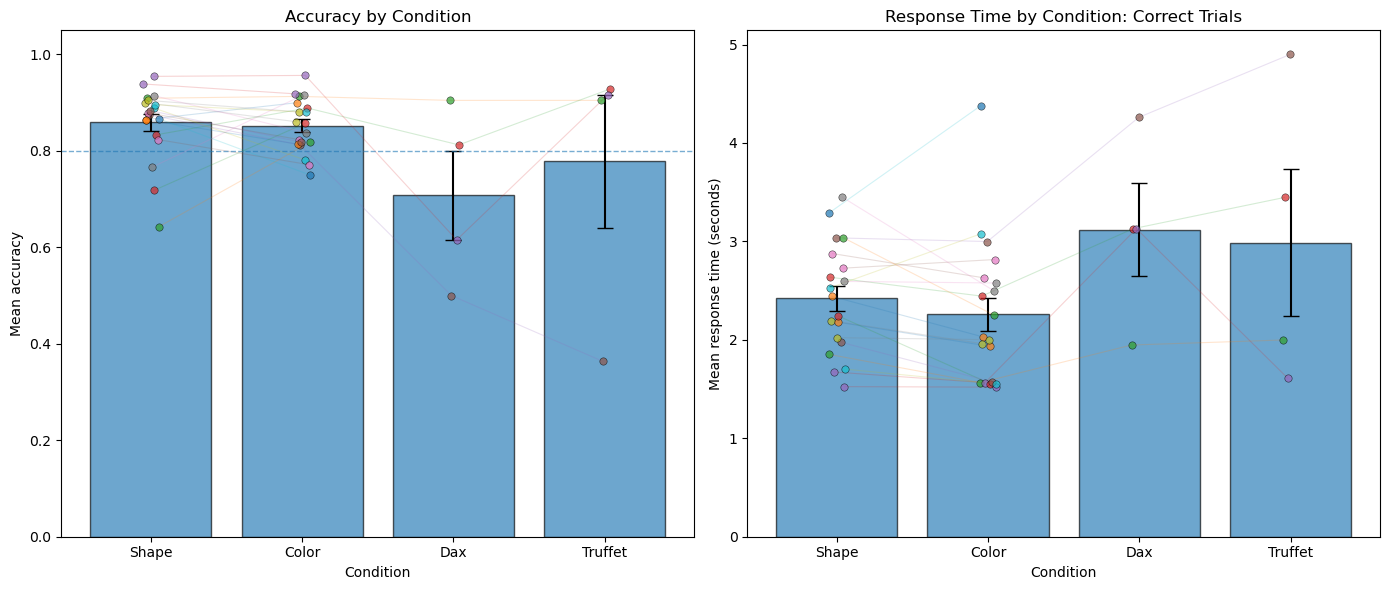


ANALYSIS COMPLETE
Participant files analyzed: 19
Output folder:
C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Kid Relmatch\kid relmatch behavioral\behavioral_analysis_outputs
Plot saved to:
C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Kid Relmatch\kid relmatch behavioral\behavioral_analysis_outputs\group_accuracy_and_response_time.png
RT means were calculated from correct trials only.
No upper or lower RT exclusion limits were applied.


In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ============================================================
# USER SETTINGS
# ============================================================

# Folder containing all participant CSV files
data_dir = (
    r"C:\Users\pkell\OneDrive\Documents\fNIRS\pilot data\Kid Relmatch\kid relmatch behavioral"
)

# Analyze RTs from correct trials only.
# Set to False to include all trials with a recorded RT.
RT_CORRECT_TRIALS_ONLY = True

# Optional RT exclusion limits
APPLY_RT_LIMITS = False
MIN_RT_SECONDS = 0.20
MAX_RT_SECONDS = 10.00

# Accuracy threshold for identifying low-performing participants
LOW_ACCURACY_THRESHOLD = 0.80

# Folder where output tables and plots will be saved
output_dir = os.path.join(
    data_dir,
    'behavioral_analysis_outputs'
)

os.makedirs(output_dir, exist_ok=True)


# ============================================================
# DEFINE THE FOUR CONDITIONS
# ============================================================

condition_columns = {
    'Shape': {
        'accuracy': 'key_resp_shape.corr',
        'rt': 'key_resp_shape.rt'
    },
    'Color': {
        'accuracy': 'key_resp_color.corr',
        'rt': 'key_resp_color.rt'
    },
    'Dax': {
        'accuracy': 'key_resp_dax.corr',
        'rt': 'key_resp_dax.rt'
    },
    'Truffet': {
        'accuracy': 'key_resp_truffet.corr',
        'rt': 'key_resp_truffet.rt'
    }
}

condition_order = [
    'Shape',
    'Color',
    'Dax',
    'Truffet'
]


# ============================================================
# FIND CSV FILES
# ============================================================

csv_files = sorted(
    glob.glob(os.path.join(data_dir, '*.csv'))
)

if len(csv_files) == 0:
    raise FileNotFoundError(
        f'No CSV files were found in:\n{data_dir}'
    )

print(
    f'Found {len(csv_files)} CSV files in:\n'
    f'{data_dir}'
)


# ============================================================
# LOAD AND RESHAPE PARTICIPANT DATA
# ============================================================

all_trial_data = []
file_summary_rows = []

for file_path in csv_files:

    filename = os.path.basename(file_path)
    participant_id = os.path.splitext(filename)[0]

    print(f'\nReading: {filename}')

    try:
        df = pd.read_csv(file_path)
    except Exception as exc:
        print(
            f'  Skipping file because it could not be read: {exc}'
        )
        continue

    participant_condition_data = []
    conditions_found = []

    for condition_name, columns in condition_columns.items():

        accuracy_column = columns['accuracy']
        rt_column = columns['rt']

        # Some earlier experiment files may not contain all four
        # conditions. Skip only the missing condition rather than
        # skipping the entire participant file.
        if (
            accuracy_column not in df.columns
            and rt_column not in df.columns
        ):
            print(
                f'  {condition_name}: response columns not present'
            )
            continue

        conditions_found.append(condition_name)

        # Create temporary numeric vectors
        if accuracy_column in df.columns:
            accuracy_values = pd.to_numeric(
                df[accuracy_column],
                errors='coerce'
            )
        else:
            accuracy_values = pd.Series(
                np.nan,
                index=df.index
            )

        if rt_column in df.columns:
            rt_values = pd.to_numeric(
                df[rt_column],
                errors='coerce'
            )
        else:
            rt_values = pd.Series(
                np.nan,
                index=df.index
            )

        # Keep rows that contain an accuracy or RT value
        usable_rows = (
            accuracy_values.notna()
            | rt_values.notna()
        )

        condition_df = pd.DataFrame({
            'participant': participant_id,
            'source_file': filename,
            'condition': condition_name,
            'accuracy': accuracy_values.loc[usable_rows],
            'rt': rt_values.loc[usable_rows]
        })

        condition_df = condition_df.reset_index(
            drop=True
        )

        print(
            f'  {condition_name}: '
            f'{len(condition_df)} behavioral rows'
        )

        participant_condition_data.append(condition_df)

    if len(participant_condition_data) == 0:
        print(
            '  No usable behavioral condition columns found. '
            'Skipping this file.'
        )
        continue

    participant_long = pd.concat(
        participant_condition_data,
        ignore_index=True
    )

    all_trial_data.append(participant_long)

    file_summary_rows.append({
        'participant': participant_id,
        'source_file': filename,
        'conditions_found': ', '.join(conditions_found),
        'number_conditions_found': len(conditions_found),
        'total_behavioral_rows': len(participant_long)
    })


if len(all_trial_data) == 0:
    raise RuntimeError(
        'No usable behavioral data were found in the CSV files.'
    )


# ============================================================
# COMBINE ALL PARTICIPANTS
# ============================================================

full_data = pd.concat(
    all_trial_data,
    ignore_index=True
)

file_summary = pd.DataFrame(file_summary_rows)

full_data['condition'] = pd.Categorical(
    full_data['condition'],
    categories=condition_order,
    ordered=True
)

print('\n============================================================')
print('FILES AND CONDITIONS FOUND')
print('============================================================')

print(
    file_summary.to_string(index=False)
)


# ============================================================
# VALIDATE ACCURACY VALUES
# ============================================================

accuracy_data = full_data.loc[
    full_data['accuracy'].notna()
].copy()

unexpected_accuracy_values = sorted(
    accuracy_data.loc[
        ~accuracy_data['accuracy'].isin([0, 1]),
        'accuracy'
    ].dropna().unique()
)

if len(unexpected_accuracy_values) > 0:
    print(
        '\nWarning: unexpected accuracy values were found:'
    )
    print(unexpected_accuracy_values)

# Keep only standard binary accuracy values
accuracy_data = accuracy_data.loc[
    accuracy_data['accuracy'].isin([0, 1])
].copy()


# ============================================================
# PREPARE RESPONSE-TIME DATA
# ============================================================

rt_data = full_data.loc[
    full_data['rt'].notna()
].copy()

# Exclude nonpositive RT values
rt_data = rt_data.loc[
    rt_data['rt'] > 0
].copy()

if RT_CORRECT_TRIALS_ONLY:

    # RT analyses are generally conducted on correct trials only
    rt_data = rt_data.loc[
        rt_data['accuracy'] == 1
    ].copy()

if APPLY_RT_LIMITS:

    rt_data = rt_data.loc[
        rt_data['rt'].between(
            MIN_RT_SECONDS,
            MAX_RT_SECONDS,
            inclusive='both'
        )
    ].copy()


# ============================================================
# REPORT TRIAL COUNTS
# ============================================================

accuracy_trial_counts = (
    accuracy_data
    .groupby(
        ['participant', 'condition'],
        observed=False
    )
    .size()
    .reset_index(name='accuracy_trial_count')
)

rt_trial_counts = (
    rt_data
    .groupby(
        ['participant', 'condition'],
        observed=False
    )
    .size()
    .reset_index(name='rt_trial_count')
)

print('\n============================================================')
print('TOTAL TRIAL COUNTS BY CONDITION')
print('============================================================')

total_trial_counts = pd.DataFrame({
    'condition': condition_order
})

total_trial_counts['accuracy_trials'] = (
    total_trial_counts['condition']
    .map(
        accuracy_data
        .groupby('condition', observed=False)
        .size()
    )
    .fillna(0)
    .astype(int)
)

total_trial_counts['rt_trials'] = (
    total_trial_counts['condition']
    .map(
        rt_data
        .groupby('condition', observed=False)
        .size()
    )
    .fillna(0)
    .astype(int)
)

print(
    total_trial_counts.to_string(index=False)
)


# ============================================================
# PARTICIPANT-LEVEL CONDITION MEANS
# ============================================================

participant_accuracy = (
    accuracy_data
    .groupby(
        ['participant', 'condition'],
        observed=False
    )
    .agg(
        accuracy_mean=('accuracy', 'mean'),
        accuracy_trial_count=('accuracy', 'count')
    )
    .reset_index()
)

participant_accuracy = participant_accuracy.loc[
    participant_accuracy['accuracy_trial_count'] > 0
].copy()


participant_rt = (
    rt_data
    .groupby(
        ['participant', 'condition'],
        observed=False
    )
    .agg(
        rt_mean=('rt', 'mean'),
        rt_trial_count=('rt', 'count')
    )
    .reset_index()
)

participant_rt = participant_rt.loc[
    participant_rt['rt_trial_count'] > 0
].copy()


participant_summary = pd.merge(
    participant_accuracy,
    participant_rt,
    on=[
        'participant',
        'condition'
    ],
    how='outer'
)

participant_summary['condition'] = pd.Categorical(
    participant_summary['condition'],
    categories=condition_order,
    ordered=True
)

participant_summary = participant_summary.sort_values(
    [
        'participant',
        'condition'
    ]
).reset_index(drop=True)


# ============================================================
# FUNCTION FOR STANDARD ERROR
# ============================================================

def calculate_se(values):
    """
    Calculate the standard error across participant-level means.
    """
    values = pd.to_numeric(
        values,
        errors='coerce'
    ).dropna()

    if len(values) < 2:
        return np.nan

    return stats.sem(
        values,
        nan_policy='omit'
    )


# ============================================================
# GROUP-LEVEL ACCURACY SUMMARY
# ============================================================

group_accuracy = (
    participant_summary
    .groupby(
        'condition',
        observed=False
    )
    .agg(
        accuracy_mean=('accuracy_mean', 'mean'),
        accuracy_sd=('accuracy_mean', 'std'),
        accuracy_se=('accuracy_mean', calculate_se),
        accuracy_n=('accuracy_mean', 'count')
    )
    .reset_index()
)


# ============================================================
# GROUP-LEVEL RESPONSE-TIME SUMMARY
# ============================================================

group_rt = (
    participant_summary
    .groupby(
        'condition',
        observed=False
    )
    .agg(
        rt_mean=('rt_mean', 'mean'),
        rt_sd=('rt_mean', 'std'),
        rt_se=('rt_mean', calculate_se),
        rt_n=('rt_mean', 'count')
    )
    .reset_index()
)


# ============================================================
# MERGE GROUP SUMMARIES
# ============================================================

group_summary = pd.merge(
    group_accuracy,
    group_rt,
    on='condition',
    how='outer'
)

group_summary['condition'] = pd.Categorical(
    group_summary['condition'],
    categories=condition_order,
    ordered=True
)

group_summary = group_summary.sort_values(
    'condition'
).reset_index(drop=True)


# ============================================================
# OPTIONAL 95% CONFIDENCE INTERVALS
# ============================================================

group_summary['accuracy_ci95'] = (
    group_summary['accuracy_se']
    * stats.t.ppf(
        0.975,
        group_summary['accuracy_n'] - 1
    )
)

group_summary['rt_ci95'] = (
    group_summary['rt_se']
    * stats.t.ppf(
        0.975,
        group_summary['rt_n'] - 1
    )
)


# ============================================================
# PRINT PARTICIPANT-LEVEL RESULTS
# ============================================================

print('\n============================================================')
print('PARTICIPANT-LEVEL CONDITION MEANS')
print('============================================================')

print(
    participant_summary[
        [
            'participant',
            'condition',
            'accuracy_mean',
            'accuracy_trial_count',
            'rt_mean',
            'rt_trial_count'
        ]
    ].round(4).to_string(index=False)
)


# ============================================================
# PRINT GROUP-LEVEL RESULTS
# ============================================================

print('\n============================================================')
print('GROUP-LEVEL BEHAVIORAL SUMMARY')
print('SE is calculated across participant-level means')
print('============================================================')

print(
    group_summary[
        [
            'condition',
            'accuracy_mean',
            'accuracy_sd',
            'accuracy_se',
            'accuracy_n',
            'rt_mean',
            'rt_sd',
            'rt_se',
            'rt_n'
        ]
    ].round(4).to_string(index=False)
)


# ============================================================
# IDENTIFY LOW-ACCURACY PARTICIPANTS
# ============================================================

accuracy_wide = participant_summary.pivot(
    index='participant',
    columns='condition',
    values='accuracy_mean'
)

low_accuracy = accuracy_wide.loc[
    (
        accuracy_wide
        < LOW_ACCURACY_THRESHOLD
    ).any(axis=1)
].reset_index()

print('\n============================================================')
print(
    f'PARTICIPANTS BELOW '
    f'{LOW_ACCURACY_THRESHOLD * 100:.0f}% '
    f'ACCURACY IN AT LEAST ONE CONDITION'
)
print('============================================================')

if low_accuracy.empty:
    print(
        'No participants were below the threshold '
        'in any available condition.'
    )
else:
    print(
        low_accuracy.round(4).to_string(index=False)
    )


# ============================================================
# SAVE OUTPUT TABLES
# ============================================================

full_data.to_csv(
    os.path.join(
        output_dir,
        'trial_level_behavioral_data.csv'
    ),
    index=False
)

participant_summary.to_csv(
    os.path.join(
        output_dir,
        'participant_condition_summary.csv'
    ),
    index=False
)

group_summary.to_csv(
    os.path.join(
        output_dir,
        'group_condition_summary.csv'
    ),
    index=False
)

low_accuracy.to_csv(
    os.path.join(
        output_dir,
        'participants_below_accuracy_threshold.csv'
    ),
    index=False
)

file_summary.to_csv(
    os.path.join(
        output_dir,
        'file_loading_summary.csv'
    ),
    index=False
)

total_trial_counts.to_csv(
    os.path.join(
        output_dir,
        'total_trial_counts.csv'
    ),
    index=False
)


# ============================================================
# GROUP-LEVEL PLOTS
# ============================================================

# Reindex ensures the conditions always appear in the desired order
plot_summary = (
    group_summary
    .set_index('condition')
    .reindex(condition_order)
    .reset_index()
)

x_positions = np.arange(
    len(condition_order)
)

# Use a fixed random generator so participant jitter is reproducible
rng = np.random.default_rng(seed=12345)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)


# ------------------------------------------------------------
# ACCURACY PLOT
# ------------------------------------------------------------

axes[0].bar(
    x_positions,
    plot_summary['accuracy_mean'],
    yerr=plot_summary['accuracy_se'],
    capsize=6,
    alpha=0.65,
    edgecolor='black',
    linewidth=1
)

for participant in participant_summary['participant'].unique():

    participant_data = (
        participant_summary.loc[
            participant_summary['participant'] == participant
        ]
        .set_index('condition')
        .reindex(condition_order)
    )

    participant_values = (
        participant_data['accuracy_mean']
        .to_numpy(dtype=float)
    )

    valid = np.isfinite(participant_values)

    if not valid.any():
        continue

    jitter = rng.uniform(
        -0.06,
        0.06
    )

    axes[0].scatter(
        x_positions[valid] + jitter,
        participant_values[valid],
        s=28,
        alpha=0.70,
        edgecolor='black',
        linewidth=0.4,
        zorder=3
    )

    if valid.sum() > 1:
        axes[0].plot(
            x_positions[valid] + jitter,
            participant_values[valid],
            alpha=0.20,
            linewidth=0.8,
            zorder=2
        )

axes[0].set_xticks(x_positions)
axes[0].set_xticklabels(condition_order)

axes[0].set_ylim(0, 1.05)

axes[0].set_xlabel('Condition')
axes[0].set_ylabel('Mean accuracy')
axes[0].set_title('Accuracy by Condition')

axes[0].axhline(
    LOW_ACCURACY_THRESHOLD,
    linestyle='--',
    linewidth=1,
    alpha=0.60
)


# ------------------------------------------------------------
# RESPONSE-TIME PLOT
# ------------------------------------------------------------

axes[1].bar(
    x_positions,
    plot_summary['rt_mean'],
    yerr=plot_summary['rt_se'],
    capsize=6,
    alpha=0.65,
    edgecolor='black',
    linewidth=1
)

for participant in participant_summary['participant'].unique():

    participant_data = (
        participant_summary.loc[
            participant_summary['participant'] == participant
        ]
        .set_index('condition')
        .reindex(condition_order)
    )

    participant_values = (
        participant_data['rt_mean']
        .to_numpy(dtype=float)
    )

    valid = np.isfinite(participant_values)

    if not valid.any():
        continue

    jitter = rng.uniform(
        -0.06,
        0.06
    )

    axes[1].scatter(
        x_positions[valid] + jitter,
        participant_values[valid],
        s=28,
        alpha=0.70,
        edgecolor='black',
        linewidth=0.4,
        zorder=3
    )

    if valid.sum() > 1:
        axes[1].plot(
            x_positions[valid] + jitter,
            participant_values[valid],
            alpha=0.20,
            linewidth=0.8,
            zorder=2
        )

axes[1].set_xticks(x_positions)
axes[1].set_xticklabels(condition_order)

axes[1].set_xlabel('Condition')
axes[1].set_ylabel('Mean response time (seconds)')

if RT_CORRECT_TRIALS_ONLY:
    axes[1].set_title(
        'Response Time by Condition: Correct Trials'
    )
else:
    axes[1].set_title(
        'Response Time by Condition: All Trials'
    )


plt.tight_layout()

plot_path = os.path.join(
    output_dir,
    'group_accuracy_and_response_time.png'
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ============================================================
# FINAL REPORT
# ============================================================

print('\n============================================================')
print('ANALYSIS COMPLETE')
print('============================================================')

print(
    f'Participant files analyzed: '
    f'{full_data["participant"].nunique()}'
)

print(
    f'Output folder:\n{output_dir}'
)

print(
    f'Plot saved to:\n{plot_path}'
)

if RT_CORRECT_TRIALS_ONLY:
    print(
        'RT means were calculated from correct trials only.'
    )
else:
    print(
        'RT means were calculated from all trials with an RT.'
    )

if APPLY_RT_LIMITS:
    print(
        f'RT values were restricted to '
        f'{MIN_RT_SECONDS:.2f}–'
        f'{MAX_RT_SECONDS:.2f} seconds.'
    )
else:
    print(
        'No upper or lower RT exclusion limits were applied.'
    )